# Dự báo xu hướng bằng Logistic Regression

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'src').exists():
    root = root.parent
sys.path.insert(0, str(root / 'src'))
from utils import *
from IPython.display import display, Image, Markdown


## Objective

So sánh financial only với event tổng quát và event categories. Không chọn tham số trên Test.

## Load Data và Validate Data

Đọc lại dữ liệu và kiểm tra trước khi fit.

In [2]:
from data_validation import run as validate
d, status = validate()
assert status == 'READY FOR ML'

READY FOR ML errors=0


## Preprocessing

Train 2021–2024 (128 mẫu), Test 2025 (32 mẫu). Pipeline scaler chỉ fit Train; event giữ đơn vị cờ/đếm. CAR dự báo xử lý theo dictionary trong bản sao.

## Model

Dummy most_frequent và Logistic mặc định L2, C=1, max_iter=1000, random_state=42. Model 2A giữ co_su_kien; Model 2B giữ mọi loại và cảnh báo event hiếm.

In [3]:
from logistic_model import run
performance, coefficients = run(d)
display(performance)
display(coefficients)

,Model,Features,Accuracy,Precision,Recall,F1,ROC-AUC
0,Baseline,-,0.50000,0.500000,1.0000,0.666667,0.500000
1,Financial Only,"roa, roe, nim, npl, car, ldr",0.50000,0.500000,0.9375,0.652174,0.535156
2,Financial + General Event,"roa, roe, nim, npl, car, ldr, co_su_kien",0.62500,0.600000,0.7500,0.666667,0.570312
3,Financial + Event Categories,"roa, roe, nim, npl, car, ldr, sk_tang_von, sk_...",0.59375,0.571429,0.7500,0.648649,0.546875


,Model,feature,coefficient,abs_coefficient,direction,unit
19,Financial + Event Categories,sk_tang_von,-0.714647,0.714647,ngược chiều,1 đơn vị sự kiện
13,Financial + Event Categories,roa,0.637617,0.637617,cùng chiều,1 SD Train
20,Financial + Event Categories,sk_chuyen_doi_so,0.540167,0.540167,cùng chiều,1 đơn vị sự kiện
21,Financial + Event Categories,sk_hop_tac_trung_thau,0.503241,0.503241,cùng chiều,1 đơn vị sự kiện
24,Financial + Event Categories,sk_khac,-0.471929,0.471929,ngược chiều,1 đơn vị sự kiện
23,Financial + Event Categories,sk_chinh_sach_nhnn,0.436850,0.436850,cùng chiều,1 đơn vị sự kiện
17,Financial + Event Categories,car,-0.434218,0.434218,ngược chiều,1 SD Train
14,Financial + Event Categories,roe,-0.389562,0.389562,ngược chiều,1 SD Train
22,Financial + Event Categories,sk_doi_lanh_dao,-0.386774,0.386774,ngược chiều,1 đơn vị sự kiện
18,Financial + Event Categories,ldr,0.093233,0.093233,cùng chiều,1 SD Train


## Evaluation và Visualization

Đánh giá cả Accuracy, Precision, Recall, F1, ROC-AUC và confusion matrix; cùng ngưỡng 0.5.

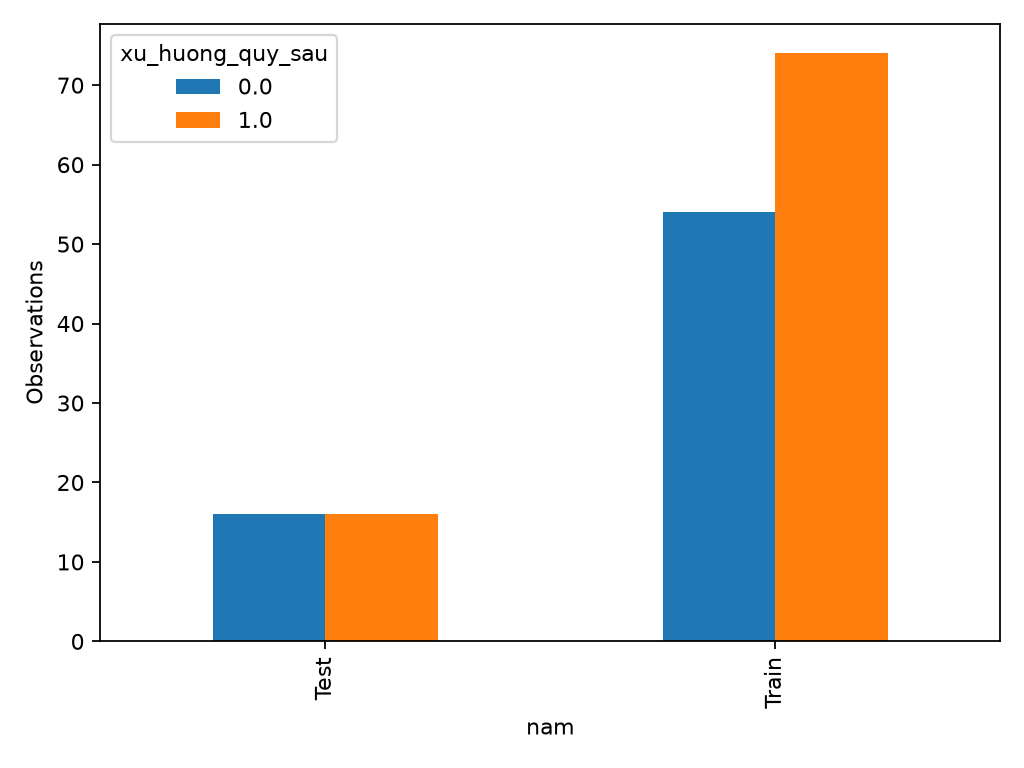

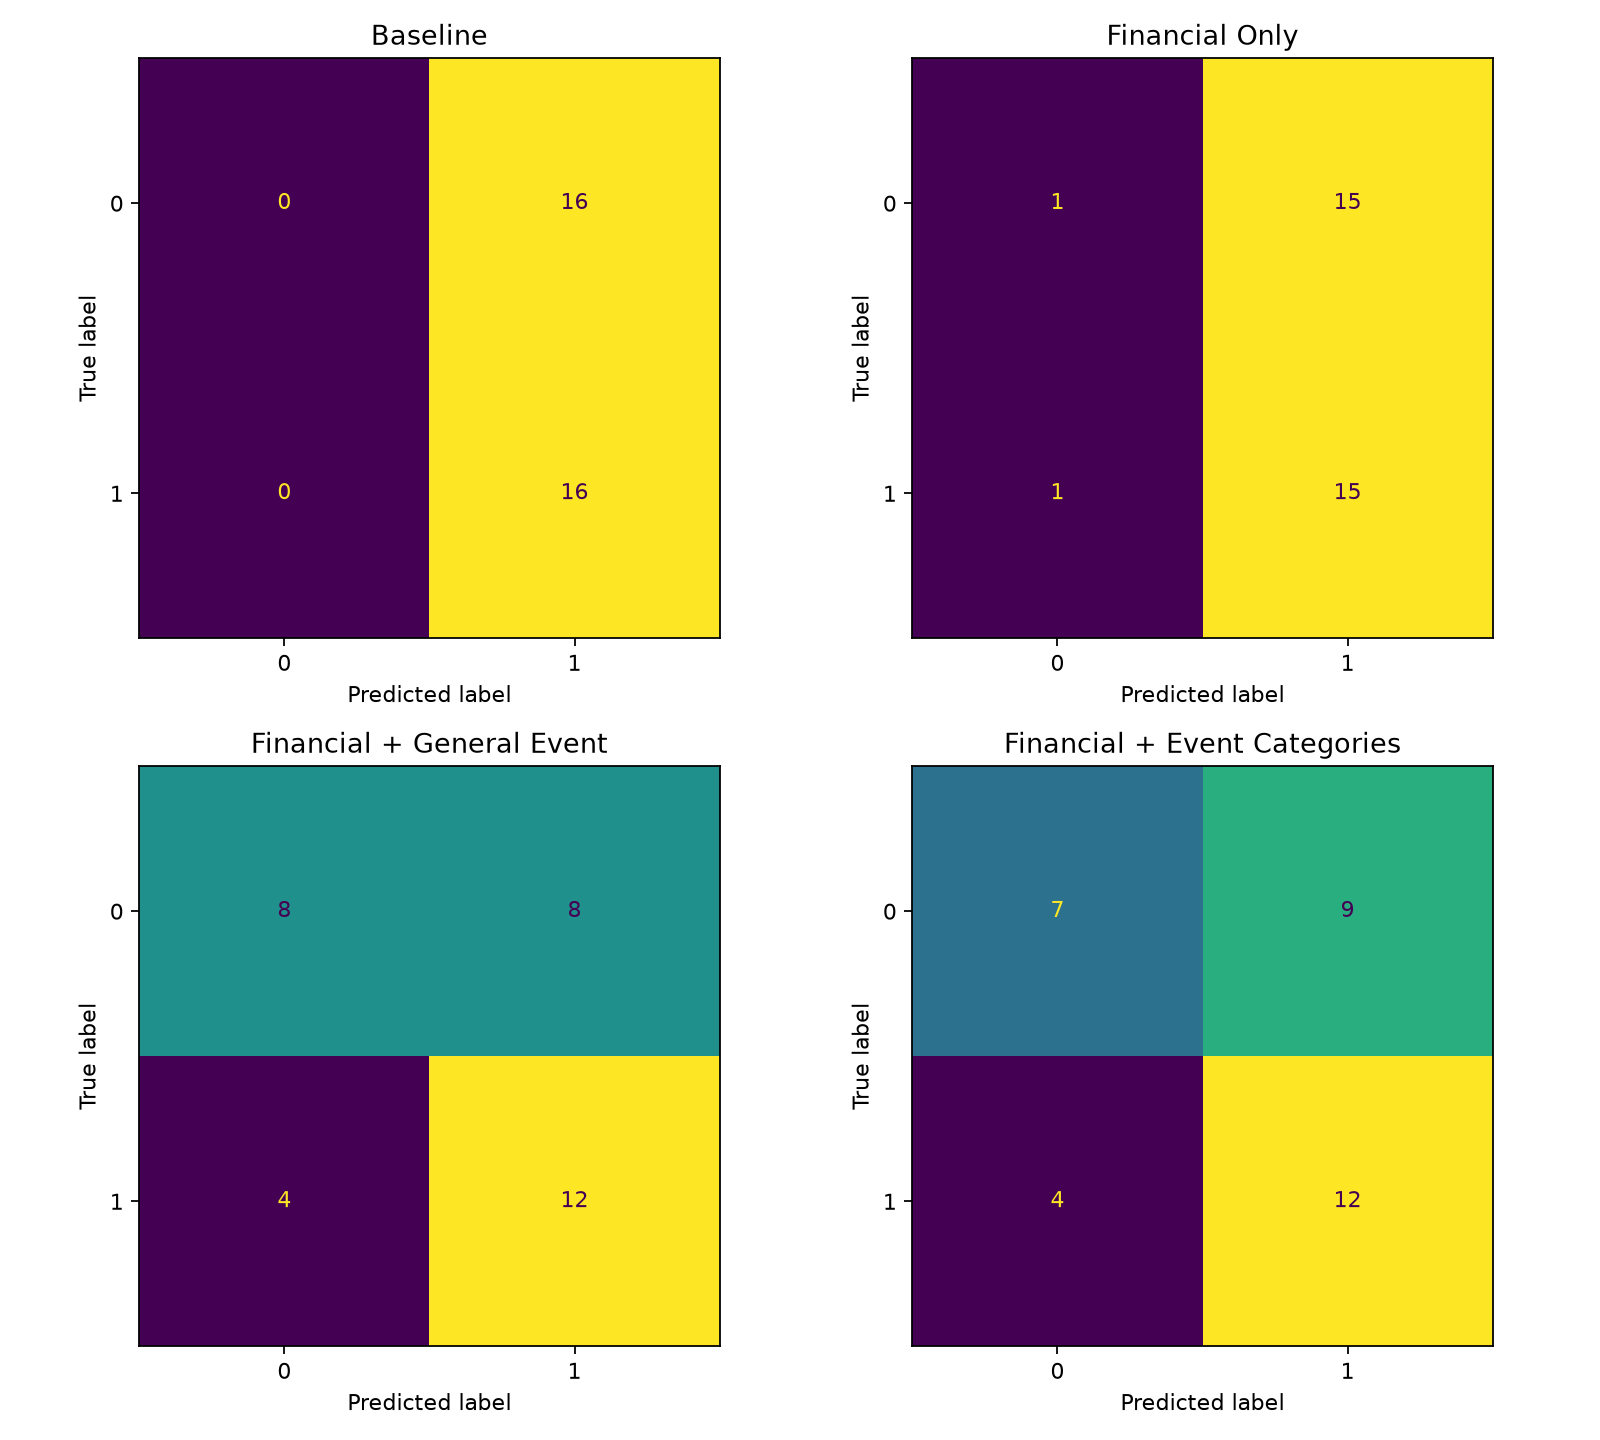

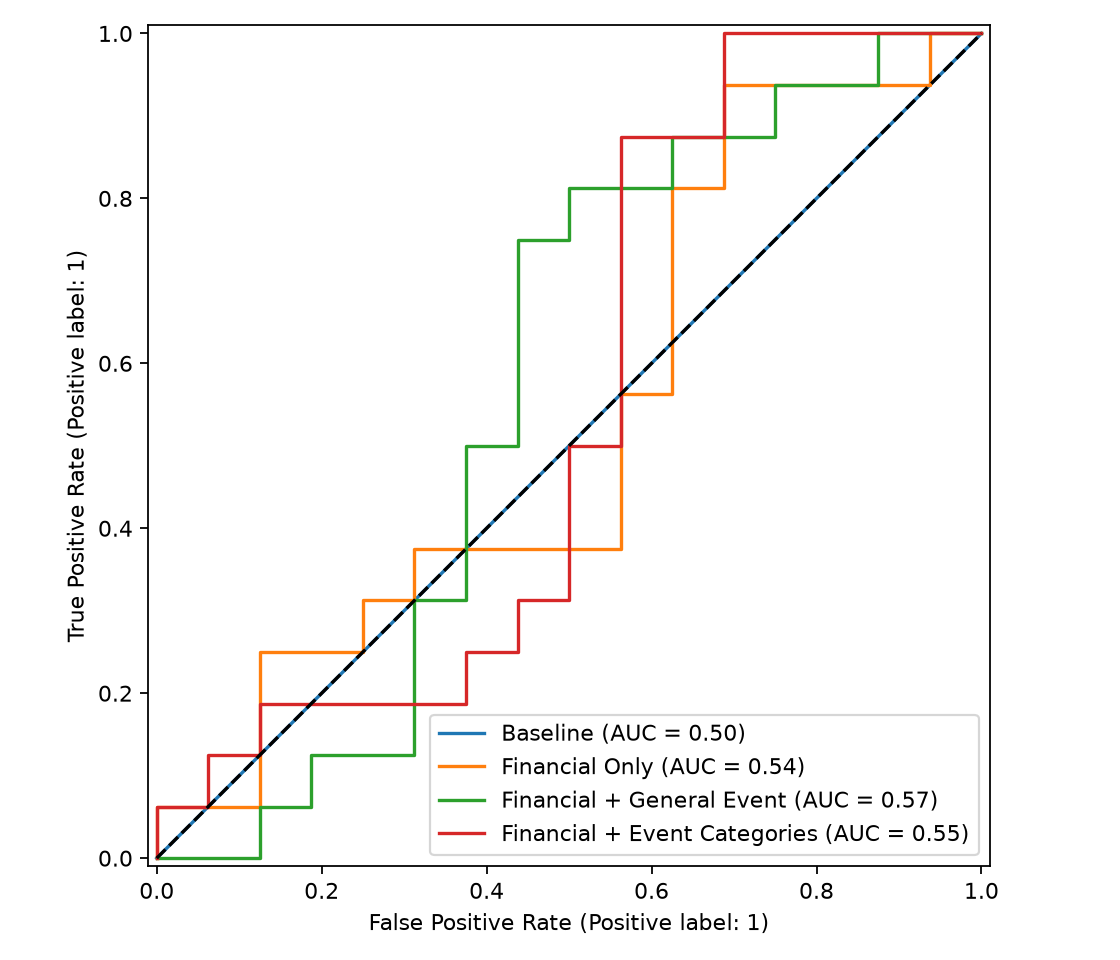

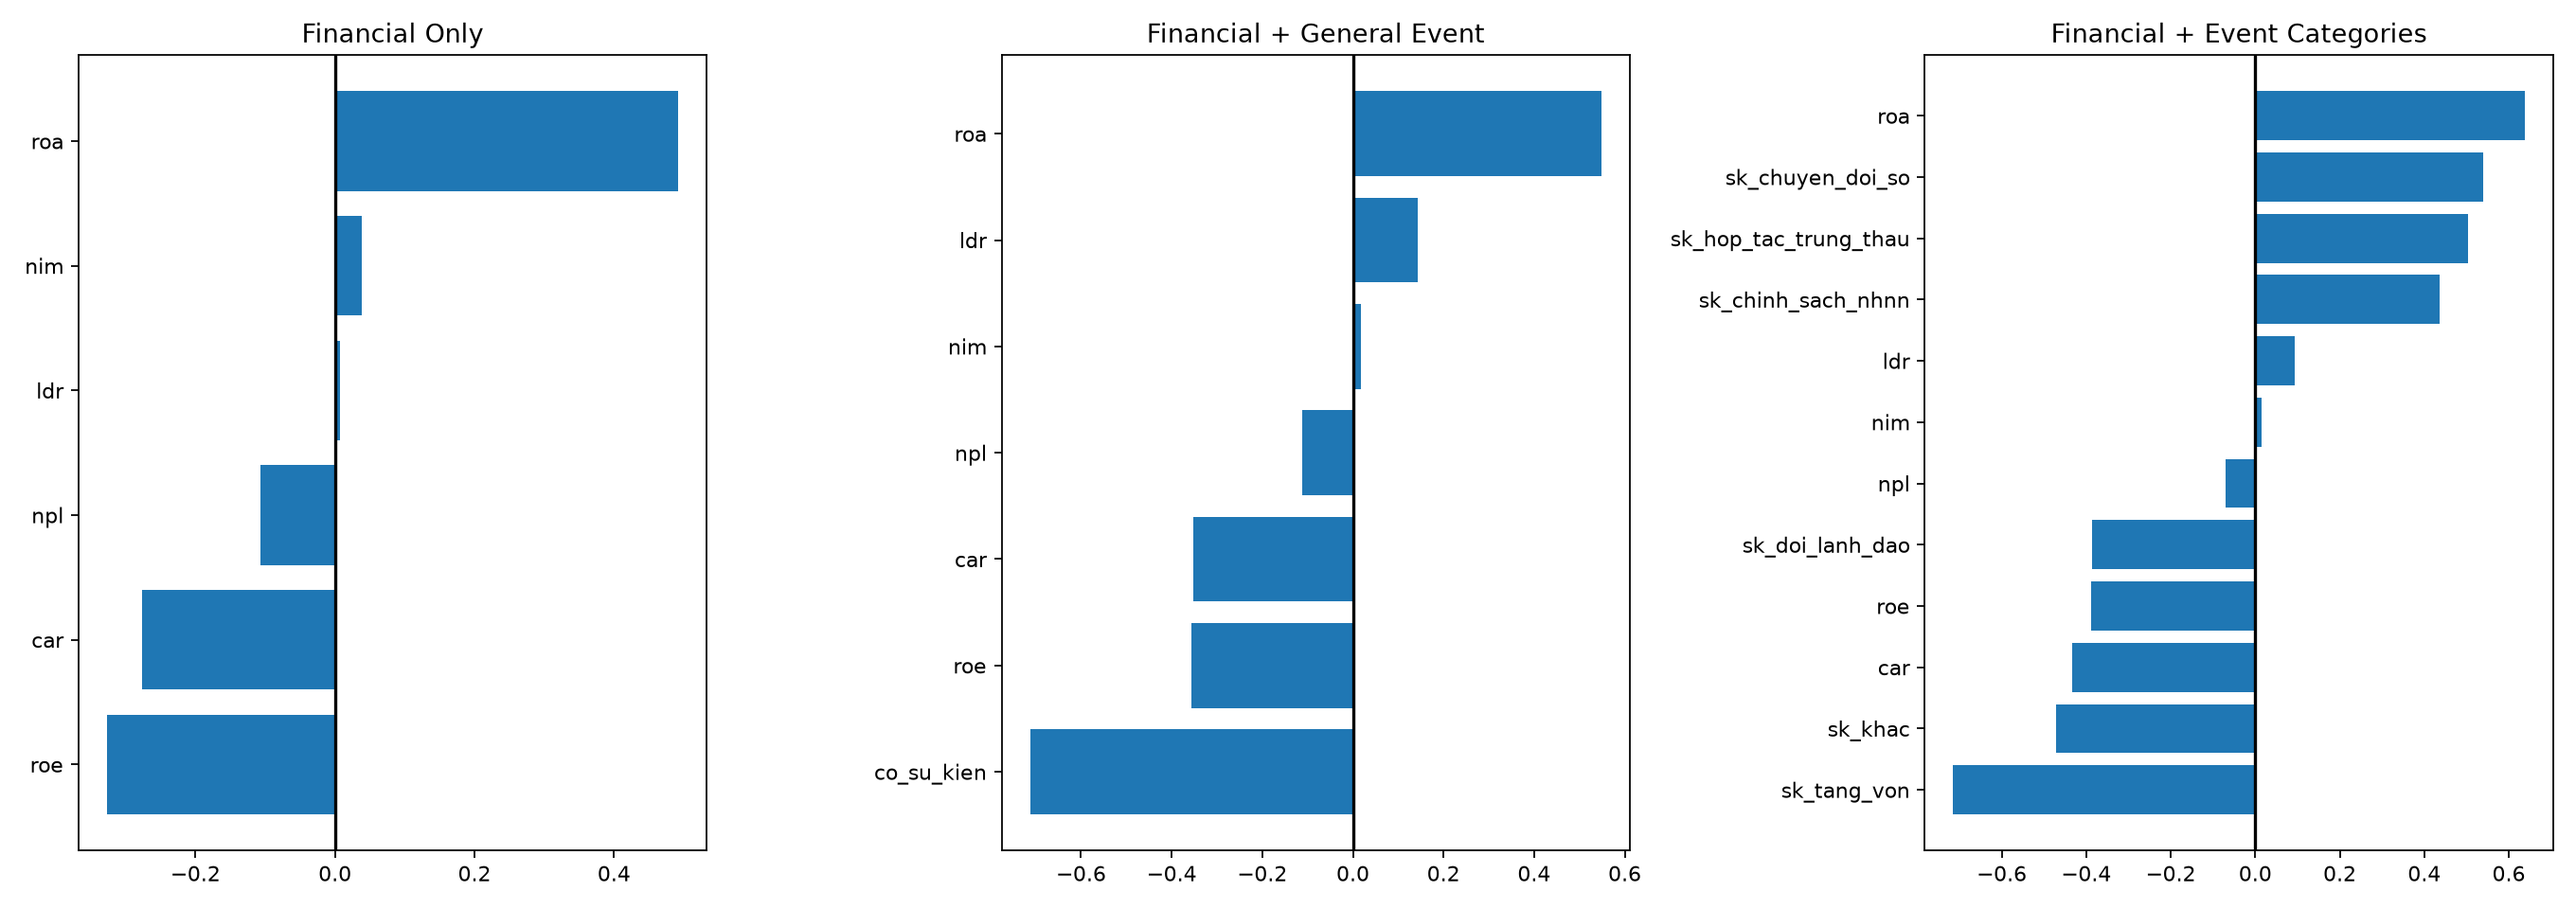

In [4]:
for name in ['target_distribution','confusion_matrices','roc_curves','logistic_coefficients']:
    display(Image(filename=str(FIGURES / f'{name}.png')))

## Interpretation và Conclusion

Hệ số biểu thị association, không suy luận nhân quả. Event không được scale như financial nên không so trực tiếp hệ số giữa hai nhóm. Với Test nhỏ, chênh lệch nhỏ chưa đủ khẳng định cải thiện ổn định.